# 00 – Main: run the whole project

Runs the steps of the project in order (see `report/project_flow_with_files.png`). Select the kernel and choose **Run All**.
All steps take about 11 minutes, most of it `04_models.ipynb` (about 6) and `04b_model_choice.ipynb` (about 5).

| Step | Notebook | Tasks | Output |
|---|---|---|---|
| 1 Data | `01_preprocess.ipynb` | 6–12 | `data/processed/building_clean.csv` |
| 2 Explore | `02_describe.ipynb` | 13–15 | descriptive tables and figures |
| 3 Split & pipeline | `03_split_pipeline.ipynb` | 16, checks 17, 19 | `data/processed/cv.csv`, `test.csv` |
| 4 Models | `04_models.ipynb` | 18, 20–23 | `output/tables/models_*.csv` |
| 4b Model choice | `04b_model_choice.ipynb` | 26 (choice) | `output/tables/choice_*.csv` |
| 5 Evaluation | `05_evaluation.ipynb` | 24, 26, 27 | `output/tables/evaluation_*.csv` |

`%run` runs every notebook in the memory of this one, so a variable from an earlier notebook is still there in a
later one. Each notebook must therefore also run on its own: restart the kernel, open it and choose Run All (task 33).

In [1]:
%pip install nbformat

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [nbformat]6/7 [nbformat]a]specifications]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# reload changed .py files (cv.py, pipeline.py, metrics.py, config.py) before every cell,
# so a running kernel never uses an old version of them
%load_ext autoreload
%autoreload 2

import numpy as np
from config import SEED  # the one project seed, defined in config.py

np.random.seed(SEED)

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


Heating file: 249398 rows, 21206 buildings, years 0 to 2026
Register: 87421 rows, 87421 buildings
Rows that are duplicated: 1047
Do all copies have the same value? True
Rows after cleaning: 248859
Buildings with a 3-year average from 2023 : 16587


,EGID,ref_year,y,heated_floor_area,building_type
70267,1013338,2023,555.0,1377,Eglise
172708,2036675,2023,370.0,253,Habitation un logement
69988,1013417,2023,480.0,2541,Hab. - rez activités
70169,1013266,2023,517.0,1055,Habitation - activités
171981,2036972,2023,455.0,1739,Bureaux
...,...,...,...,...,...
203096,3132099,2026,314.0,810,Hab plusieurs logements
23279,1006454,2026,314.0,1069,Habitation - activités
230213,295119457,2026,156.0,1490,Hab plusieurs logements
144299,1030897,2026,212.0,1642,Habitation - activités


Buildings removed as implausible: 25
Buildings kept: 16562
    construction_period_code construction_period  energy_source_code energy_source
0                        NaN                 NaN                 NaN           NaN
1                     8017.0           1986-1990              7530.0        Heizöl
2                     8014.0           1961-1970              7530.0        Heizöl
4                     8015.0           1971-1980              7530.0        Heizöl
6                     8013.0           1946-1960              7530.0        Heizöl
7                     8016.0           1981-1985              7530.0        Heizöl
9                     8013.0           1946-1960              7520.0           Gas
11                    8017.0           1986-1990              7520.0           Gas
Missing values after this step, among buildings with a target:
construction_period_code     83
energy_source_code          188
heating_system_code         414
building_class_code          13
flo

,count,median
ANNEE,,
2011,15626,499.0
2012,16061,508.0
2013,16245,511.0
2014,16260,495.0
2015,15851,490.0
2016,15819,477.0
2017,15817,476.0
2018,15902,486.0
2019,15941,470.0



Target by reference year:
          count  median
ref_year               
2023        816   422.0
2024       1390   409.0
2025       8036   387.0
2026       6320   382.0

Same buildings, period ending in 2023 vs 2026: 6067 buildings, median 432.0 -> 383.0 | median change: -43.0

Option B (only periods ending in 2025) would keep: 14267 buildings, 1077 houses
Option A (latest period from 2023 on) keeps: 16562 buildings, 1531 houses


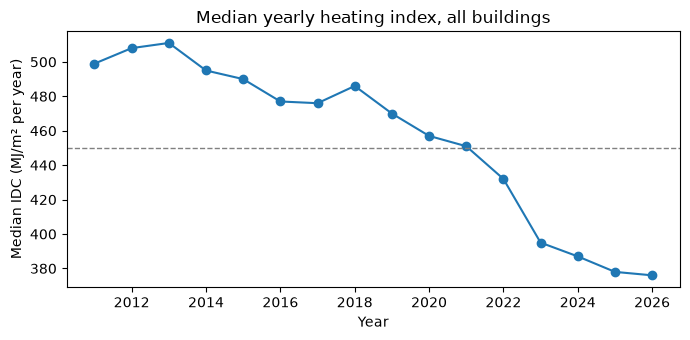

          all buildings (%)  houses (%)
ref_year                               
2023                    4.9        12.3
2024                    8.4        15.2
2025                   48.5        50.8
2026                   38.2        21.8

Share ending in 2025 or 2026, all buildings: 86.7 %
Share ending in 2025 or 2026, houses: 72.6 %

Houses by reference year:
          count  median
ref_year               
2023        188   450.5
2024        232   381.0
2025        777   421.0
2026        334   413.0
Removed, not in the register: 107
Removed, not an existing building: 3
Buildings left: 16452 | houses: 1531
Houses: 1531
Houses that switched: 65
Share of houses that switched: 4.2 %
Houses with other in their switch: 20

energy_group
other → heat pump      16
district heat → oil    13
gas → heat pump         9
oil → heat pump         6
gas → gas               4

Buildings removed because they switched: 697
Houses removed because they switched: 65
Buildings left: 15755 | Houses left: 14

In [3]:
%run 01_preprocess.ipynb

In [4]:
# %run 02_describe.ipynb   # activate when 02_describe.ipynb is in the repository (tasks 13-15)

In [5]:
%run 03_split_pipeline.ipynb

Buildings: 14827 | houses: 1366 | groups: 12866
Test set: 2117 buildings, 195 houses
Buildings without a fold (should be the test set): 2117


,buildings,houses,groups,share of buildings (%),house share (%),houses above 450 (%)
part,,,,,,
0,2542,234,2207,17.1,9.2,36.3
1,2545,235,2205,17.2,9.2,39.6
2,2541,234,2209,17.1,9.2,37.6
3,2541,234,2202,17.1,9.2,38.9
4,2541,234,2203,17.1,9.2,37.6
test,2117,195,1840,14.3,9.2,35.9


Groups split across parts: 0
Saved cv.csv: 12710 buildings | test.csv: 2117 buildings
1.0
0.5
0.75
0.0
Overall mean: 400.0
{'A|gas': 300.0, 'B|oil': 520.0, 'C|wood': 440.0}
[300. 400.]
{'A|gas': 200.0, 'B|oil': 1000.0, 'C|wood': 600.0}
Columns after preprocessing: 92
Missing values after preprocessing: 0
Expert-rule column present: True

Overall mean, learned: 395.04 | folds 1-4: 395.04 | all buildings in cross-validation: 395.84
Buildings counted in the expert rule: 10168 | buildings in folds 1-4: 10168


Buildings in cross-validation: 12710 | of which houses: 1171
Training mean, baseline                            
Expert rule, baseline                              
Linear regression, reference                       
Linear regression, no expert rule                  
Ridge, reference                                   best alpha = 562
Ridge, no expert rule                              best alpha = 0.01
Lasso, reference                                   best alpha = 0.001
Lasso, no expert rule                              best alpha = 0.631
Logistic regression, reference                     best C = 10
Logistic regression, no expert rule                best C = 10
Linear regression, no municipality                 
Linear regression, no heating                      
Linear regression, no heating, no municipality     
Ridge, no municipality                             best alpha = 0.01
Ridge, no heating                                  best alpha = 31.6
Ridge, no heating, no municipality

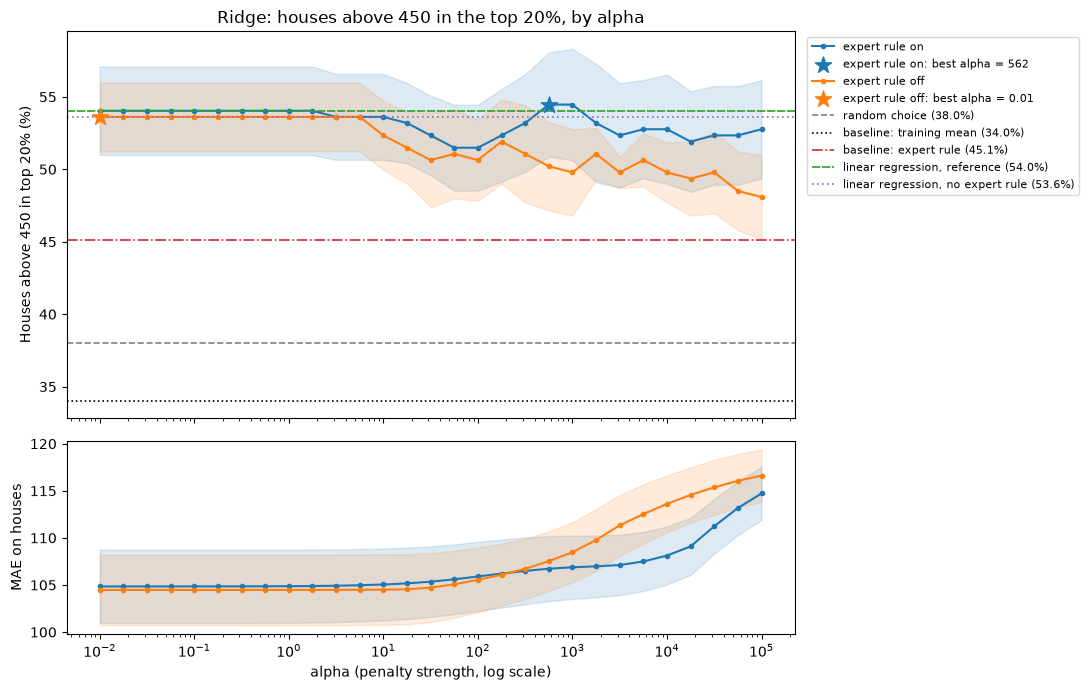

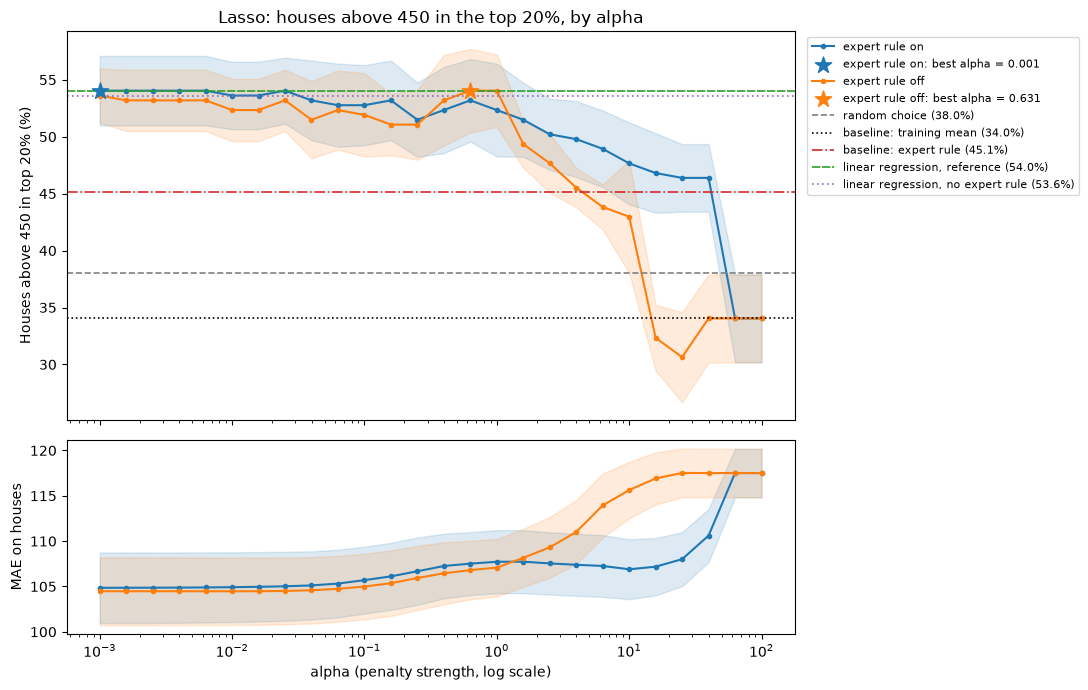

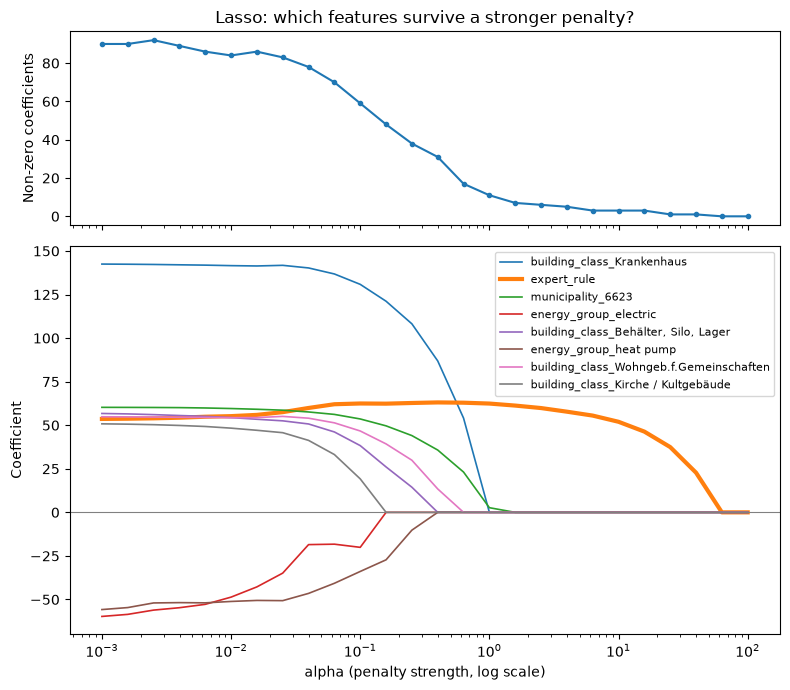

Houses above 450: 38.0 %
All buildings above 450: 29.0 %


,expert_rule,C,top 20%: above 450 (%),± SE
0,True,0.001,53.2,4.1
1,True,0.010,51.9,3.6
2,True,0.100,52.8,2.5
3,True,1.000,53.2,2.7
4,True,10.000,53.6,2.9
5,True,100.000,53.6,2.9
6,False,0.001,49.8,1.6
7,False,0.010,53.2,3.4
8,False,0.100,51.5,2.6
9,False,1.000,53.6,2.0


Best: Logistic regression, no expert rule | C = 10.0


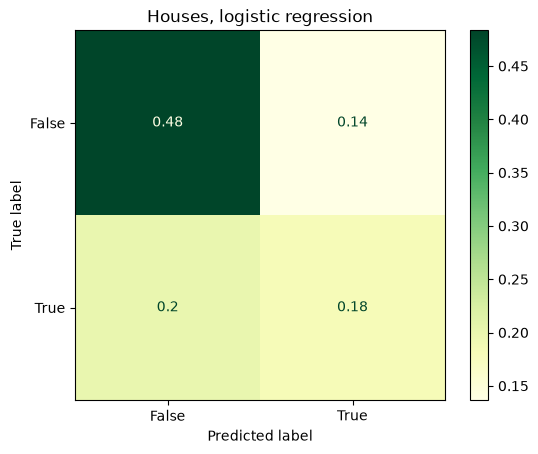

Accuracy : 0.664 | baseline: 0.62
Precision: 0.57
Recall   : 0.476
F1       : 0.519
AUC      : 0.687
AUC logistic: 0.687


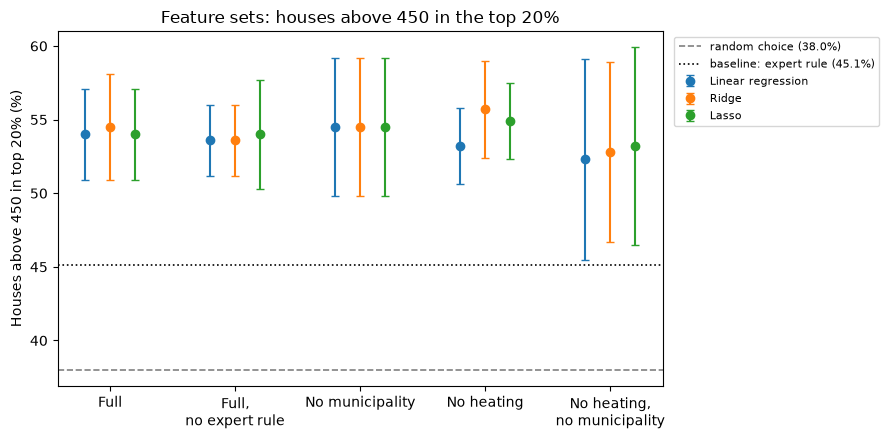

Linear regression
      A: all buildings (%)  B: houses only (%)  B minus A (points)
fold                                                              
0                     46.8                55.3                 8.5
1                     46.8                55.3                 8.5
2                     61.7                55.3                -6.4
3                     57.4                68.1                10.6
4                     57.4                55.3                -2.1
Houses only better in 3 of 5 folds, worse in 2 of 5 folds | mean difference +3.8 points (± 3.4 SE)

Ridge
      A: all buildings (%)  B: houses only (%)  B minus A (points)
fold                                                              
0                     46.8                57.4                10.6
1                     53.2                59.6                 6.4
2                     61.7                59.6                -2.1
3                     63.8                68.1                 4.3
4    

In [6]:
%run 04_models.ipynb

In [ ]:
%run 04b_model_choice.ipynb

Model analysed: Linear regression, reference
Buildings: 12710 | houses: 1171
Houses
       true value  prediction
count      1171.0      1171.0
mean        426.0       425.0
std         152.0        69.0
min          74.0       236.0
25%         321.0       383.0
50%         417.0       438.0
75%         514.0       472.0
max        1499.0       583.0

All buildings
       true value  prediction
count     12710.0     12710.0
mean        396.0       396.0
std         126.0        74.0
min          50.0        19.0
25%         319.0       361.0
50%         390.0       407.0
75%         465.0       443.0
max        1499.0       660.0

Predictions below 50: 2 | below 0: 0 | above 1,500: 0
Spread of predictions vs. true values (houses): 69 vs. 152


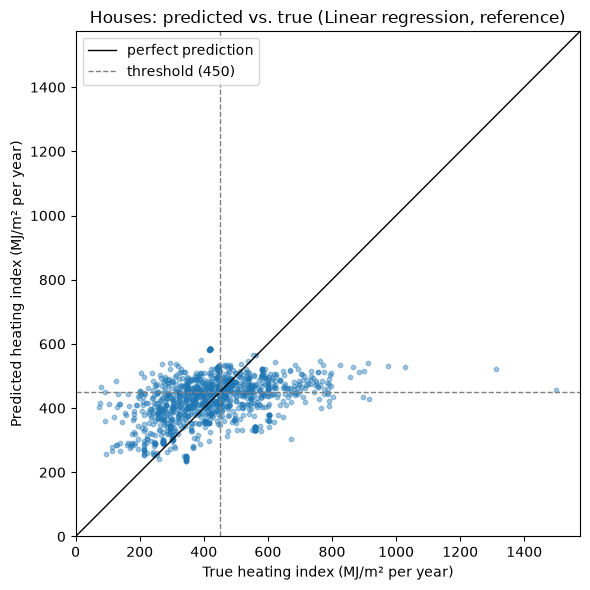

               n  mean_error    mae
true band                          
(0, 250]     115       162.0  162.0
(250, 350]   271        89.3  101.1
(350, 450]   340        35.8   57.5
(450, 550]   224       -43.9   52.5
(550, 700]   164      -164.6  164.8
(700, 1500]   57      -323.6  323.6


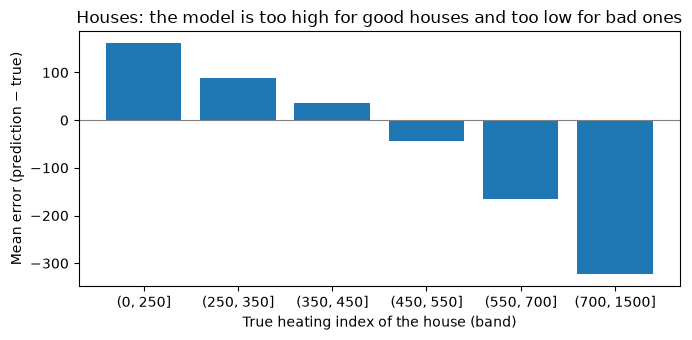

outcome
correctly left out    618
missed                318
hit                   127
false alarm           108

Share of hits among contacted houses: 54.0 % (should be close to 54% from task 20)
True value of false alarms:
count    108.0
mean     381.0
std       68.0
min      127.0
25%      341.0
50%      408.0
75%      442.0
max      450.0

False alarms just below the threshold (400–450): 56 of 108

True and predicted value of missed problem houses:
            y   pred
count   318.0  318.0
mean    565.0  430.0
std     105.0   43.0
min     451.0  303.0
25%     485.0  407.0
50%     548.0  443.0
75%     602.0  463.0
max    1499.0  485.0
Construction period (% of each column)
outcome               hit  false alarm  missed  correctly left out
construction_period                                               
Vor 1919              8.7          7.4    26.4                16.2
1919-1945            11.8          9.3    12.6                 6.8
1946-1960            15.7         25.9     3.5  

In [7]:
%run 05_evaluation.ipynb